# 02 – Statistical analysis

Second part of Data Understanding. Notebook 01 used simple 1D/2D summaries; here we use **hypothesis tests** and **multivariate methods** (PCA, clustering, multivariable models) to answer specific questions that matter for tasks (a) and (b).

| Section | Method | Question |
|---|---|---|
| 1 | Correlation matrix (Spearman) | Which team statistics are redundant? |
| 2 | PCA | Are there a few underlying "dimensions" of a team? |
| 3 | k-means on PCA | Are there team profiles, and do they relate to success and coach changes? |
| 4 | Pythagorean expectation + regression | Do "lucky" teams fall back the next season? |
| 5 | Mann-Whitney, chi-square | Are coach changes related to last season's results? |
| 6 | Coach tenure + logistic regression | Are new coaches fired faster, after controlling for results? |

Scope: NHL seasons from **1967** (the expansion from 6 to 12 teams; power-play statistics exist from 1963), so the game is comparable to today's.

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LogisticRegression

con = sqlite3.connect("../data/hockey.db")
q = lambda sql: pd.read_sql(sql, con)
sql_file = lambda name: q(open(f"../sql/{name}").read())

sns.set_theme(style="whitegrid")
RNG = 42

## 0. Data

- [`sql/team_features.sql`](../sql/team_features.sql): per-game statistics for each team-season.
- [`sql/coach_changes.sql`](../sql/coach_changes.sql): coach-change flags (from notebook 01).

We add the previous season's values of each team (same franchise, consecutive season; 2005 follows 2003).

In [2]:
teams = sql_file("team_features.sql")
coach = sql_file("coach_changes.sql")[["franchID", "year", "first_coach", "last_coach", "n_coaches", "changed_between"]]

FEATS = ["pts_pct", "gf_pg", "ga_pg", "gd_pg", "pim_pg", "pp_pct", "pk_pct", "pp_opp_pg", "shf_pg", "pyth_pct", "made_playoffs"]
prev = teams[["franchID", "year"] + FEATS].copy()
prev["year"] = np.where(prev.year == 2003, 2005, prev.year + 1)   # value at t-1 is attached to season t
prev = prev.rename(columns={c: c + "_prev" for c in FEATS})

df = (teams.merge(prev, on=["franchID", "year"], how="left")
           .merge(coach, on=["franchID", "year"], how="left"))
print(df.shape, "team-seasons,", df.year.min(), "to", df.year.max())
df.head()

(938, 31) team-seasons, 1967 to 2009


,year,franchID,tmID,name,G,pts_pct,gf_pg,ga_pg,gd_pg,pim_pg,...,pp_pct_prev,pk_pct_prev,pp_opp_pg_prev,shf_pg_prev,pyth_pct_prev,made_playoffs_prev,first_coach,last_coach,n_coaches,changed_between
0,1967,BOS,BOS,Boston Bruins,74,0.567568,3.500000,2.918919,0.581081,13.932432,...,NaN,NaN,NaN,NaN,NaN,NaN,sindeha01c,sindeha01c,1,0.0
1,1967,CHI,CHI,Chicago Black Hawks,74,0.540541,2.864865,3.000000,-0.135135,8.135135,...,NaN,NaN,NaN,NaN,NaN,NaN,reaybi01c,reaybi01c,1,0.0
2,1967,CLE,OAK,Oakland Seals,74,0.317568,2.067568,2.959459,-0.891892,10.500000,...,NaN,NaN,NaN,NaN,NaN,NaN,olmstbe01c,fashogo01c,2,NaN
3,1967,DAL,MNS,Minnesota North Stars,74,0.466216,2.581081,3.054054,-0.472973,9.648649,...,NaN,NaN,NaN,NaN,NaN,NaN,blairwr01c,blairwr01c,1,NaN
4,1967,DET,DET,Detroit Red Wings,74,0.445946,3.310811,3.472973,-0.162162,10.175676,...,NaN,NaN,NaN,NaN,NaN,NaN,abelsi01c,abelsi01c,1,0.0


## 1. Which statistics are redundant?

Spearman correlation (rank-based, so robust to outliers and non-linear monotonic relations) between per-game team statistics, all from the same season.

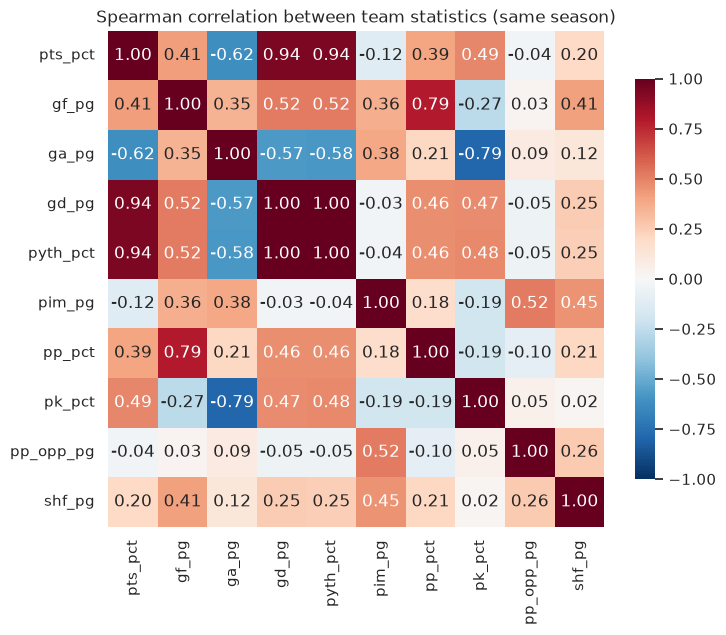

In [3]:
STATS = ["pts_pct", "gf_pg", "ga_pg", "gd_pg", "pyth_pct", "pim_pg", "pp_pct", "pk_pct", "pp_opp_pg", "shf_pg"]
corr = df[STATS].corr(method="spearman")
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Spearman correlation between team statistics (same season)");

In [4]:
# pairs of statistics with |rho| > 0.8
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.8].sort_values(key=abs, ascending=False).round(2)

gd_pg    pyth_pct    1.00
pts_pct  pyth_pct    0.94
         gd_pg       0.94
dtype: float64

## 2. PCA: the underlying dimensions of a team

Goals and penalties change a lot between eras (more goals in the 1980s, fewer after 2000). To compare teams **with their own season**, each statistic is standardised **within the season** (z-score per year) before PCA. We leave out `pts_pct`, `gd_pg` and `pyth_pct`, which are outcomes or exact combinations of other inputs, so the components describe *how* a team plays, and we check afterwards whether they relate to success.

PC1    0.346
PC2    0.211
PC3    0.142
PC4    0.128
PC5    0.093
PC6    0.043
PC7    0.037
dtype: float64

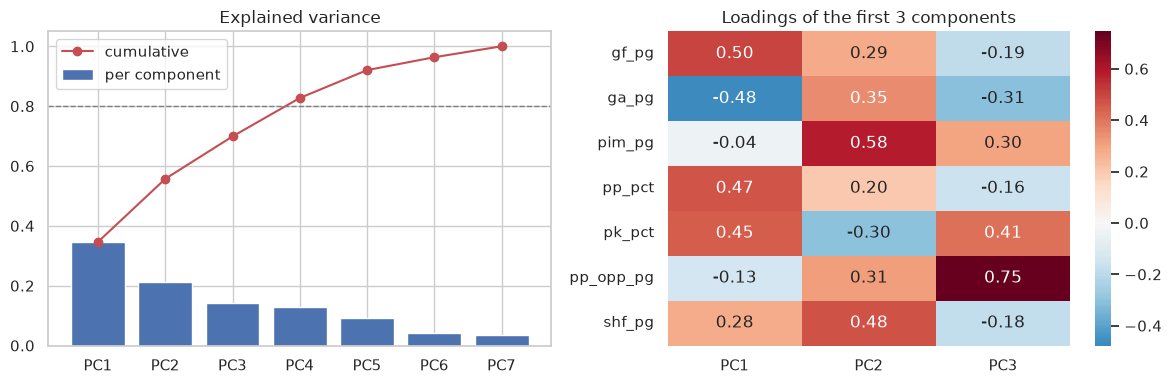

In [5]:
PCA_IN = ["gf_pg", "ga_pg", "pim_pg", "pp_pct", "pk_pct", "pp_opp_pg", "shf_pg"]
Z = df.groupby("year")[PCA_IN].transform(lambda s: (s - s.mean()) / s.std())
pca = PCA(random_state=RNG).fit(Z)
expl = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i+1}" for i in range(len(PCA_IN))])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(expl.index, expl, label="per component")
ax[0].plot(expl.index, expl.cumsum(), "o-", color="C3", label="cumulative")
ax[0].axhline(0.8, ls="--", c="grey", lw=1); ax[0].legend(); ax[0].set_title("Explained variance")
loadings = pd.DataFrame(pca.components_[:3].T, index=PCA_IN, columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1]); ax[1].set_title("Loadings of the first 3 components")
plt.tight_layout()
expl.round(3)

Spearman correlation of each component with points% (same season):
PC1    0.88
PC2   -0.08
PC3    0.05
dtype: float64


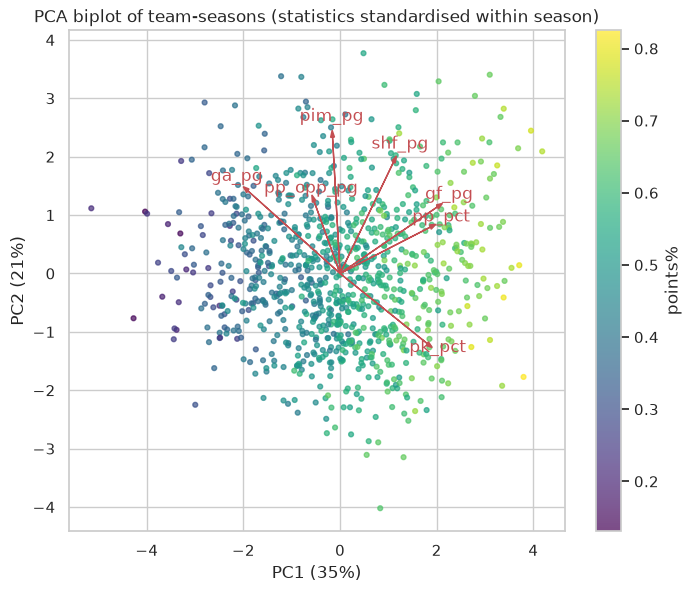

In [6]:
pcs = pd.DataFrame(pca.transform(Z)[:, :3], columns=["PC1", "PC2", "PC3"], index=df.index)
df = df.join(pcs)
print("Spearman correlation of each component with points% (same season):")
print(df[["PC1", "PC2", "PC3"]].corrwith(df.pts_pct, method="spearman").round(2))

# biplot: teams in PC1-PC2, coloured by points%, with the loading vectors
fig, ax = plt.subplots(figsize=(8, 6.5))
sc = ax.scatter(df.PC1, df.PC2, c=df.pts_pct, cmap="viridis", s=12, alpha=0.7)
plt.colorbar(sc, label="points%")
for f in PCA_IN:
    x, y = loadings.loc[f, "PC1"] * 4, loadings.loc[f, "PC2"] * 4
    ax.arrow(0, 0, x, y, color="C3", head_width=0.08)
    ax.text(x * 1.12, y * 1.12, f, color="C3", ha="center")
ax.set(xlabel=f"PC1 ({expl.PC1:.0%})", ylabel=f"PC2 ({expl.PC2:.0%})", title="PCA biplot of team-seasons (statistics standardised within season)");

## 3. Clustering: team profiles

k-means on the first 3 principal components. k is chosen with the silhouette score (how well separated the clusters are). Then we describe each cluster and check whether the profile is related to success **and to a coach change the following season**.

best k = 2


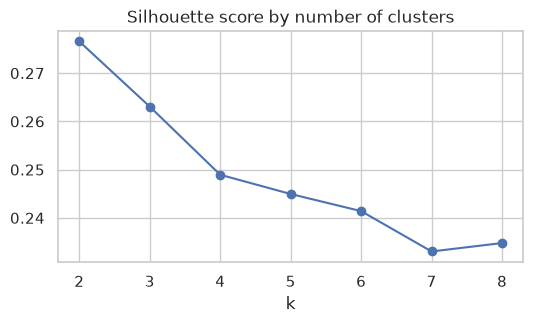

In [7]:
X3 = df[["PC1", "PC2", "PC3"]].values
sil = {k: silhouette_score(X3, KMeans(k, n_init=10, random_state=RNG).fit_predict(X3)) for k in range(2, 9)}
pd.Series(sil).plot(marker="o", title="Silhouette score by number of clusters", figsize=(6, 3)); plt.xlabel("k")
best_k = max(sil, key=sil.get)
print("best k =", best_k)

In [8]:
K = max(best_k, 4)   # at least 4 so the profiles are informative; see silhouette plot above
df["cluster"] = KMeans(K, n_init=10, random_state=RNG).fit_predict(X3)

# coach change at the START of next season, attached to this season's row
nxt = df[["franchID", "year", "changed_between"]].copy()
nxt["year"] = np.where(nxt.year == 2005, 2003, nxt.year - 1)
df = df.merge(nxt.rename(columns={"changed_between": "coach_change_next"}), on=["franchID", "year"], how="left")

profile = df.groupby("cluster").agg(
    n=("pts_pct", "size"),
    **{c: (c, "mean") for c in ["gf_pg", "ga_pg", "pim_pg", "pp_pct", "pk_pct"]},
    pts_pct=("pts_pct", "mean"),
    made_playoffs=("made_playoffs", "mean"),
    coach_change_next=("coach_change_next", "mean"),
).round(3)
profile

,n,gf_pg,ga_pg,pim_pg,pp_pct,pk_pct,pts_pct,made_playoffs,coach_change_next
cluster,,,,,,,,,
0,240,2.882,3.712,17.184,0.167,0.777,0.389,0.171,0.368
1,185,3.731,2.934,17.878,0.225,0.827,0.631,0.989,0.193
2,306,3.137,2.959,15.442,0.188,0.825,0.543,0.748,0.248
3,207,3.188,3.201,19.127,0.186,0.814,0.508,0.691,0.237


Cluster vs coach change next season: chi2=18.6, dof=3, p=0.00034


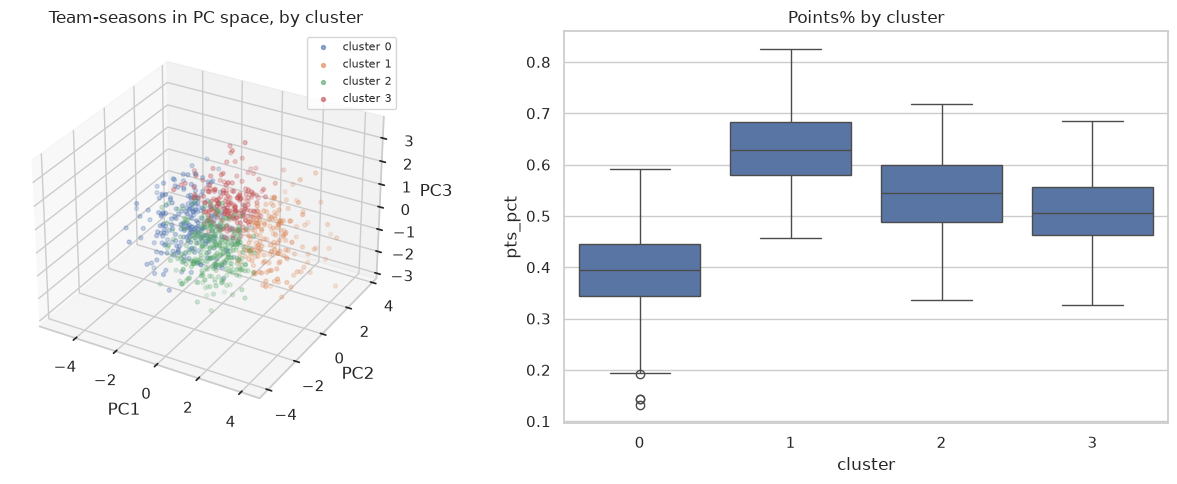

In [9]:
fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
for c in sorted(df.cluster.unique()):
    d = df[df.cluster == c]
    ax.scatter(d.PC1, d.PC2, d.PC3, s=8, alpha=0.6, label=f"cluster {c}")
ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="Team-seasons in PC space, by cluster"); ax.legend(fontsize=8)
ax2 = fig.add_subplot(1, 2, 2)
sns.boxplot(data=df, x="cluster", y="pts_pct", ax=ax2); ax2.set_title("Points% by cluster")
plt.tight_layout()

ct = pd.crosstab(df.cluster, df.coach_change_next)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Cluster vs coach change next season: chi2={chi2:.1f}, dof={dof}, p={p:.2g}")

## 4. Luck: do teams that beat their goal differential fall back?

The **Pythagorean expectation** `GF² / (GF² + GA²)` estimates the points% a team "should" get from the goals it scores and allows. The difference `pts_pct − pyth_pct` is mostly **luck** (close games, overtime, shootouts). If it is luck, it should not repeat: teams above expectation at *t-1* should drop at *t*.

Spearman(luck at t-1, change in points% t-1 -> t) = -0.21  (p = 1e-10, n = 907)
Linear fit: delta_pts = 0.012 + -0.64 * luck_prev
               mean  count
luck_group                
most unlucky  0.035    182
2             0.016    181
3             0.005    181
4            -0.002    181
most lucky   -0.028    182


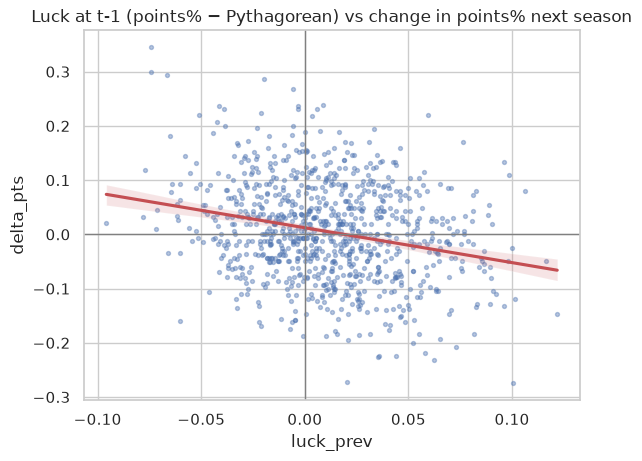

In [10]:
lk = df.dropna(subset=["pts_pct_prev"]).copy()
lk["luck_prev"] = lk.pts_pct_prev - lk.pyth_pct_prev
lk["delta_pts"] = lk.pts_pct - lk.pts_pct_prev

r, p = stats.spearmanr(lk.luck_prev, lk.delta_pts)
print(f"Spearman(luck at t-1, change in points% t-1 -> t) = {r:.2f}  (p = {p:.1g}, n = {len(lk)})")

slope, intercept, r_lin, p_lin, se = stats.linregress(lk.luck_prev, lk.delta_pts)
print(f"Linear fit: delta_pts = {intercept:.3f} + {slope:.2f} * luck_prev")

lk["luck_group"] = pd.qcut(lk.luck_prev, 5, labels=["most unlucky", "2", "3", "4", "most lucky"])
print(lk.groupby("luck_group", observed=True).delta_pts.agg(["mean", "count"]).round(3))

sns.regplot(data=lk, x="luck_prev", y="delta_pts", scatter_kws={"s": 8, "alpha": .4}, line_kws={"color": "C3"})
plt.axhline(0, c="grey", lw=1); plt.axvline(0, c="grey", lw=1)
plt.title("Luck at t-1 (points% − Pythagorean) vs change in points% next season");

In [11]:
# Which is the better predictor of next season: last season's points% or its Pythagorean points%?
for col in ["pts_pct_prev", "pyth_pct_prev", "gd_pg_prev"]:
    print(f"{col:15} Spearman with pts_pct at t: {stats.spearmanr(lk[col], lk.pts_pct)[0]:.3f}")

pts_pct_prev    Spearman with pts_pct at t: 0.647
pyth_pct_prev   Spearman with pts_pct at t: 0.636
gd_pg_prev      Spearman with pts_pct at t: 0.635


## 5. Coach changes and last season's results

`changed_between = 1` when the coach who starts season *t* is not the one who ended *t-1*.

In [12]:
cb = df.dropna(subset=["changed_between", "pts_pct_prev"]).copy()
cb["changed_between"] = cb.changed_between.astype(int)
g1, g0 = cb.loc[cb.changed_between == 1, "pts_pct_prev"], cb.loc[cb.changed_between == 0, "pts_pct_prev"]

u, p = stats.mannwhitneyu(g1, g0, alternative="less")
auc = u / (len(g1) * len(g0))   # probability a changing team had lower pts% than a non-changing one is 1 - auc
print(f"Median points% at t-1: changed coach = {g1.median():.3f}, kept coach = {g0.median():.3f}")
print(f"Mann-Whitney U (one-sided, changed < kept): p = {p:.1g}; P(changed team worse) = {1 - auc:.2f}")

ct = pd.crosstab(cb.made_playoffs_prev.map({0: "missed playoffs", 1: "made playoffs"}), cb.changed_between)
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / ct.values.sum())
print(f"\nChi-square playoffs at t-1 vs coach change: chi2 = {chi2:.1f}, p = {p:.1g}, Cramér's V = {cramers_v:.2f}")
print((ct.div(ct.sum(axis=1), axis=0)[[1]].rename(columns={1: "share changing coach"})).round(3))

Median points% at t-1: changed coach = 0.476, kept coach = 0.531
Mann-Whitney U (one-sided, changed < kept): p = 7e-08; P(changed team worse) = 0.61

Chi-square playoffs at t-1 vs coach change: chi2 = 10.4, p = 0.001, Cramér's V = 0.11
changed_between     share changing coach
made_playoffs_prev                      
made playoffs                      0.229
missed playoffs                    0.330


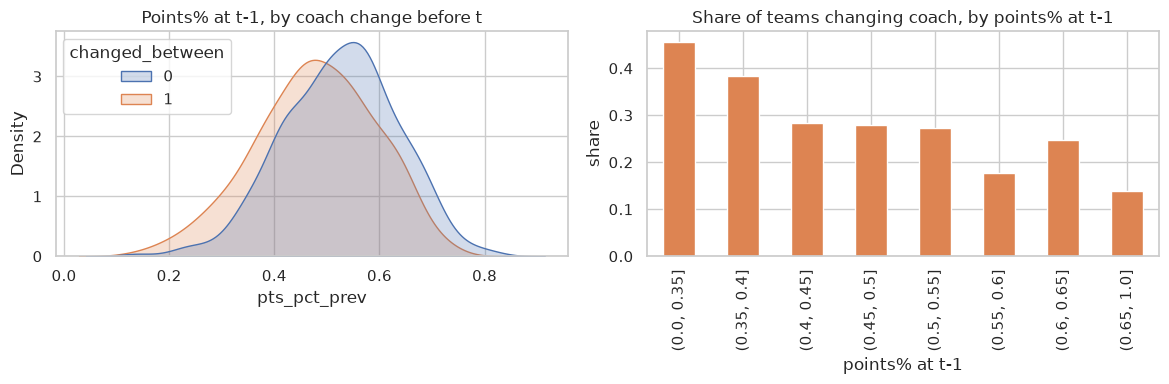

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=cb, x="pts_pct_prev", hue="changed_between", common_norm=False, fill=True, ax=ax[0])
ax[0].set_title("Points% at t-1, by coach change before t")
cb["pts_bin"] = pd.cut(cb.pts_pct_prev, [0, .35, .4, .45, .5, .55, .6, .65, 1])
cb.groupby("pts_bin", observed=True).changed_between.mean().plot(kind="bar", ax=ax[1], color="C1")
ax[1].set(title="Share of teams changing coach, by points% at t-1", ylabel="share", xlabel="points% at t-1")
plt.tight_layout()

## 6. Coach tenure: are new coaches fired faster?

Tenure = number of consecutive seasons the coach who ended season *t-1* had been in charge of that franchise. Then a **logistic regression** with tenure, points% and playoffs at *t-1* together, to see whether tenure matters **after accounting for results** (a 3+ variable analysis rather than one variable at a time).

In [14]:
cs = coach.sort_values(["franchID", "year"]).copy()
cs["prev_last"] = cs.groupby("franchID").last_coach.shift()
# tenure of last_coach at the end of each season: +1 if the same coach continued, else 1
ten = []
for _, g in cs.groupby("franchID"):
    t = 0
    for first, last, prev_last in zip(g.first_coach, g.last_coach, g.prev_last):
        t = t + 1 if (first == prev_last and last == first) else 1
        ten.append(t)
cs["tenure_end"] = ten
tn = cs[["franchID", "year", "tenure_end"]].copy()
tn["year"] = np.where(tn.year == 2003, 2005, tn.year + 1)
cb = cb.merge(tn.rename(columns={"tenure_end": "tenure_prev"}), on=["franchID", "year"], how="left")

cb["tenure_group"] = pd.cut(cb.tenure_prev, [0, 1, 2, 3, 5, 100], labels=["1", "2", "3", "4-5", "6+"])
summary = cb.groupby("tenure_group", observed=True).agg(share_changing=("changed_between", "mean"),
                                                        n=("changed_between", "size"),
                                                        mean_pts_prev=("pts_pct_prev", "mean")).round(3)
summary

,share_changing,n,mean_pts_prev
tenure_group,,,
1,0.273,399,0.471
2,0.257,222,0.515
3,0.264,121,0.546
4-5,0.281,96,0.577
6+,0.232,69,0.592


Standardised logistic regression coefficients (effect of +1 std on the log-odds of a coach change):
                    coef  odds_ratio
pts_pct_prev       -0.52        0.60
made_playoffs_prev  0.07        1.07
log_tenure_prev     0.16        1.18
luck_prev          -0.04        0.96


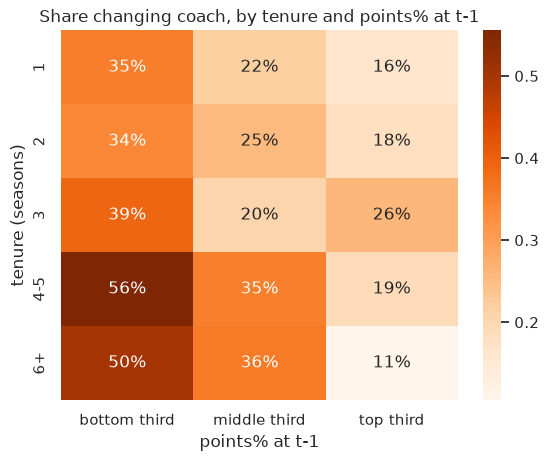

In [15]:
m = cb.dropna(subset=["tenure_prev"])
X = pd.DataFrame({
    "pts_pct_prev": m.pts_pct_prev,
    "made_playoffs_prev": m.made_playoffs_prev,
    "log_tenure_prev": np.log(m.tenure_prev),
    "luck_prev": m.pts_pct_prev - m.pyth_pct_prev,
})
Xs = (X - X.mean()) / X.std()
logit = LogisticRegression().fit(Xs, m.changed_between)
coefs = pd.Series(logit.coef_[0], index=X.columns)
print("Standardised logistic regression coefficients (effect of +1 std on the log-odds of a coach change):")
print(pd.DataFrame({"coef": coefs, "odds_ratio": np.exp(coefs)}).round(2))

# effect of tenure, holding results fixed: compare the change rate by tenure within the same points% band
m["pts_band"] = pd.qcut(m.pts_pct_prev, 3, labels=["bottom third", "middle third", "top third"])
piv = m.pivot_table(index="tenure_group", columns="pts_band", values="changed_between", aggfunc="mean", observed=True)
sns.heatmap(piv, annot=True, fmt=".0%", cmap="Oranges")
plt.title("Share changing coach, by tenure and points% at t-1"); plt.ylabel("tenure (seasons)"); plt.xlabel("points% at t-1");

## Findings

**Redundancy (section 1).** `gd_pg` and `pyth_pct` are practically the same variable (ρ = 1.00), and both correlate 0.94 with `pts_pct`. In data preparation, keep only one of them as a feature.

**Dimensions of a team (section 2).** Three components explain about 70% of the variance:
- **PC1 (35%), "overall quality":** more goals scored, fewer allowed, better power play and penalty kill. It correlates **0.88** with points%, so most of what distinguishes teams is a single quality axis.
- **PC2 (21%), "open, undisciplined game":** more penalty minutes, more goals both for and against, worse penalty kill. It is unrelated to points% (ρ = −0.08), so the style of play does not decide success.
- **PC3 (14%), "draws power plays":** opponents take more penalties against the team.

**Team profiles (section 3).** The silhouette score is low for every k (0.25–0.28), so there are **no sharply separated groups**: teams vary continuously. We used k = 4 for interpretation (silhouette 0.25, close to the best k = 2):
- **weak teams** (3.7 goals against per game; 17% make the playoffs);
- **elite teams** (3.7 goals for per game; 99% make the playoffs);
- **disciplined, defensive teams** (fewest penalty minutes);
- **physical, penalised, average teams** (most penalty minutes).

The profile is associated with a coach change the next season (χ² p < 0.001): **37%** of weak-profile teams change coach, against 19% of elite ones.

**Luck regresses to the mean (section 4).** Teams that got more points than their goal differential predicted (Pythagorean expectation) **drop the next season**, and unlucky teams improve (Spearman −0.21, p ≈ 1e-10). About **two thirds of the luck disappears** in one season (slope −0.64). Surprisingly, last season's Pythagorean points% does not predict next season better than plain points% (ρ 0.636 vs 0.647). Luck is therefore more useful as a **correction feature** (`luck_prev`) than as a replacement for points%.

**Results drive coach changes (section 5).** Teams that change coach had clearly worse points% the season before (median 0.476 vs 0.531; Mann-Whitney p ≈ 1e-7). Missing the playoffs raises the change rate from 23% to 33% (χ² p = 0.001), but the effect is weak (Cramér's V = 0.11).

**Coaches get a grace period, but patience runs out (section 6).** Looking at tenure alone, nothing changes (about 26% at every tenure). That is misleading, because long-tenured coaches have better teams. **Holding results fixed**, coaches in a bad season are replaced 35% of the time in their first season and **50–56% after 4 or more seasons**. In the logistic regression, once points% is in the model, missing the playoffs adds almost nothing (odds ratio 1.07), and longer tenure *increases* the chance of a change (OR 1.18 per std).

**Implications for the models:**
- Task (a): use `pts_pct_prev` plus `luck_prev`; drop the redundant `gd_pg` / `pyth_pct`.
- Task (b): use `pts_pct_prev`, `tenure_prev` and the interaction between them (a long-tenured coach with a bad team). `made_playoffs_prev` is mostly redundant given points%.


In [16]:
con.close()